# Flight Ticket Price Prediction — ML Course Project I (Regression Part)
**Course:** AIT511 Machine Learning 2026, IIIT Bangalore. Team submission (regression half).

**Task:** predict the ticket `price` (INR) of a domestic flight from airline, flight number, route, timings, stops, class, duration and days left before departure.

**Notebook structure** (follows the project statement and the Kaggle report requirements):
1. Problem & dataset
2. Exploratory Data Analysis
3. Data preprocessing (with justification)
4. Models: Linear Regression (OLS, Ridge), Maximum-Likelihood Estimation (from scratch), Decision Tree, Random Forest, XGBoost, CatBoost, and a blend of the best ones
5. Hyper-parameter tuning: approach and settings explored for each model
6. Results & discussion
7. Best model and final submission

**Reproducibility:** one global `SEED = 42` is passed to every CV splitter and model.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats, optimize
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
np.random.seed(SEED)

def find_dir():
    # works locally and on Kaggle
    for root in ['/kaggle/input', '.', './data', '../data', '/home/claude/reg/data']:
        if os.path.isdir(root):
            for dp, _, fs in os.walk(root):
                if {'train.csv', 'test.csv', 'sample_submission.csv'} <= set(fs):
                    if 'price' in pd.read_csv(os.path.join(dp, 'sample_submission.csv'), nrows=1).columns:
                        return dp
    raise FileNotFoundError('flight-price csv files not found')
DATA_DIR = find_dir()
OUT_DIR = 'submissions'; os.makedirs(OUT_DIR, exist_ok=True)
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
sample_sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
TARGET, ID = 'price', 'id'
RAW_FEATURES = [c for c in test.columns if c != ID]
print('train', train.shape, '| test', test.shape, '| sample submission', sample_sub.shape)
train.head()

train (15589, 12) | test (3898, 11) | sample submission (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


## 1. Problem and Dataset

* **Type:** supervised regression with a continuous target `price` (INR).
* **Train:** 15,589 rows × 11 features + `id` + `price`. **Test:** 3,898 rows. Submission: `id, price` (3,898 × 2).
* **Features:** 8 categorical (`airline`, `flight`, `source_city`, `departure_time`, `stops`, `arrival_time`, `destination_city`, `flight_class`) and 2 numeric (`duration` in hours, `days_left`).
* **Metric:** we optimise and report **R²** (coefficient of determination) on the original price scale, which matches the 0–1 scores on the Kaggle leaderboard. RMSE and MAE are reported alongside.
* Airline and city names are anonymised (fictional names), but the flight-code prefixes (`6E`, `AI`, `UK`…) are real IATA codes.

In [2]:
print(train.dtypes); print()
miss = pd.DataFrame({'train_missing': train.isna().sum(), 'train_%': (train.isna().mean()*100).round(1),
                     'test_missing': test.isna().sum().reindex(train.columns), 'test_%': (test.isna().mean()*100).round(1).reindex(train.columns)})
display(miss[miss.train_missing > 0])
display(train.describe().T.round(2))
display(pd.DataFrame({c: [train[c].nunique(), test[c].nunique()] for c in RAW_FEATURES if train[c].dtype != 'float64' and c != 'days_left'}, index=['unique in train', 'unique in test']).T)

id                    int64
airline                 str
flight                  str
source_city             str
departure_time          str
stops                   str
arrival_time            str
destination_city        str
flight_class            str
duration            float64
days_left             int64
price                 int64
dtype: object



,train_missing,train_%,test_missing,test_%
airline,3089,19.8,799.0,20.5
duration,3095,19.9,776.0,19.9


,count,mean,std,min,25%,50%,75%,max
id,15589.0,7795.00,4500.30,1.00,3898.00,7795.0,11692.00,15589.00
duration,12494.0,4.30,4.18,0.92,2.25,2.5,4.92,38.08
days_left,15589.0,22.46,13.04,1.00,12.00,22.0,33.00,57.00
price,15589.0,29816.70,39127.89,3801.00,7210.00,10183.0,35968.00,323177.00


,unique in train,unique in test
airline,18,17
flight,1070,872
source_city,6,6
departure_time,6,6
stops,3,3
arrival_time,6,6
destination_city,6,6
flight_class,2,2


## 2. Exploratory Data Analysis

### 2.1 Target distribution

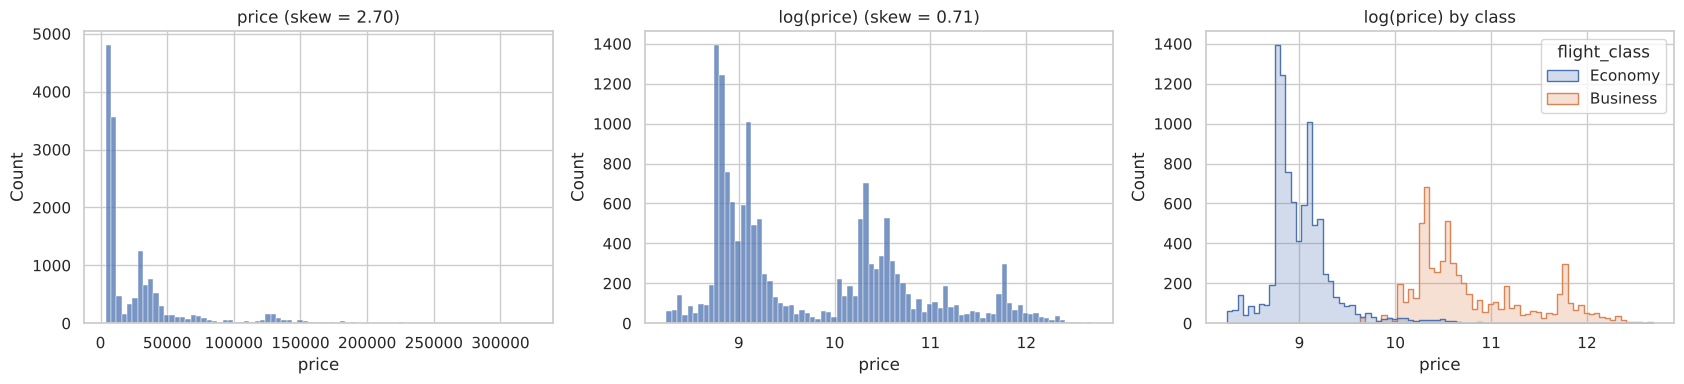

,count,mean,std,min,25%,50%,75%,max
flight_class,,,,,,,,
Business,6380.0,60127.0,46415.0,15544.0,30767.0,38546.0,70441.0,323177.0
Economy,9209.0,8818.0,4670.0,3801.0,6740.0,7587.0,9340.0,74691.0


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(train.price, bins=80, ax=ax[0]); ax[0].set_title(f'price (skew = {train.price.skew():.2f})')
sns.histplot(np.log(train.price), bins=80, ax=ax[1]); ax[1].set_title(f'log(price) (skew = {np.log(train.price).skew():.2f})')
sns.histplot(data=train, x=np.log(train.price), hue='flight_class', bins=80, ax=ax[2], element='step'); ax[2].set_title('log(price) by class')
plt.tight_layout(); plt.show()
display(train.groupby('flight_class').price.describe().round(0))

**Observations:**
* `price` is **strongly right-skewed** and **bimodal**: Business fares are ~7× Economy fares, and the two classes barely overlap.
* `log(price)` makes each class roughly symmetric and turns multiplicative effects (e.g. "Business costs ×7", "last-minute costs +20%") into additive ones. So we **model log(price)** and transform predictions back with exp (checked empirically in Section 4).
* Business fares have a long tail (up to ₹3.2 lakh). These few very large values dominate squared-error metrics such as R² (see 2.7).

### 2.2 Price vs categorical features

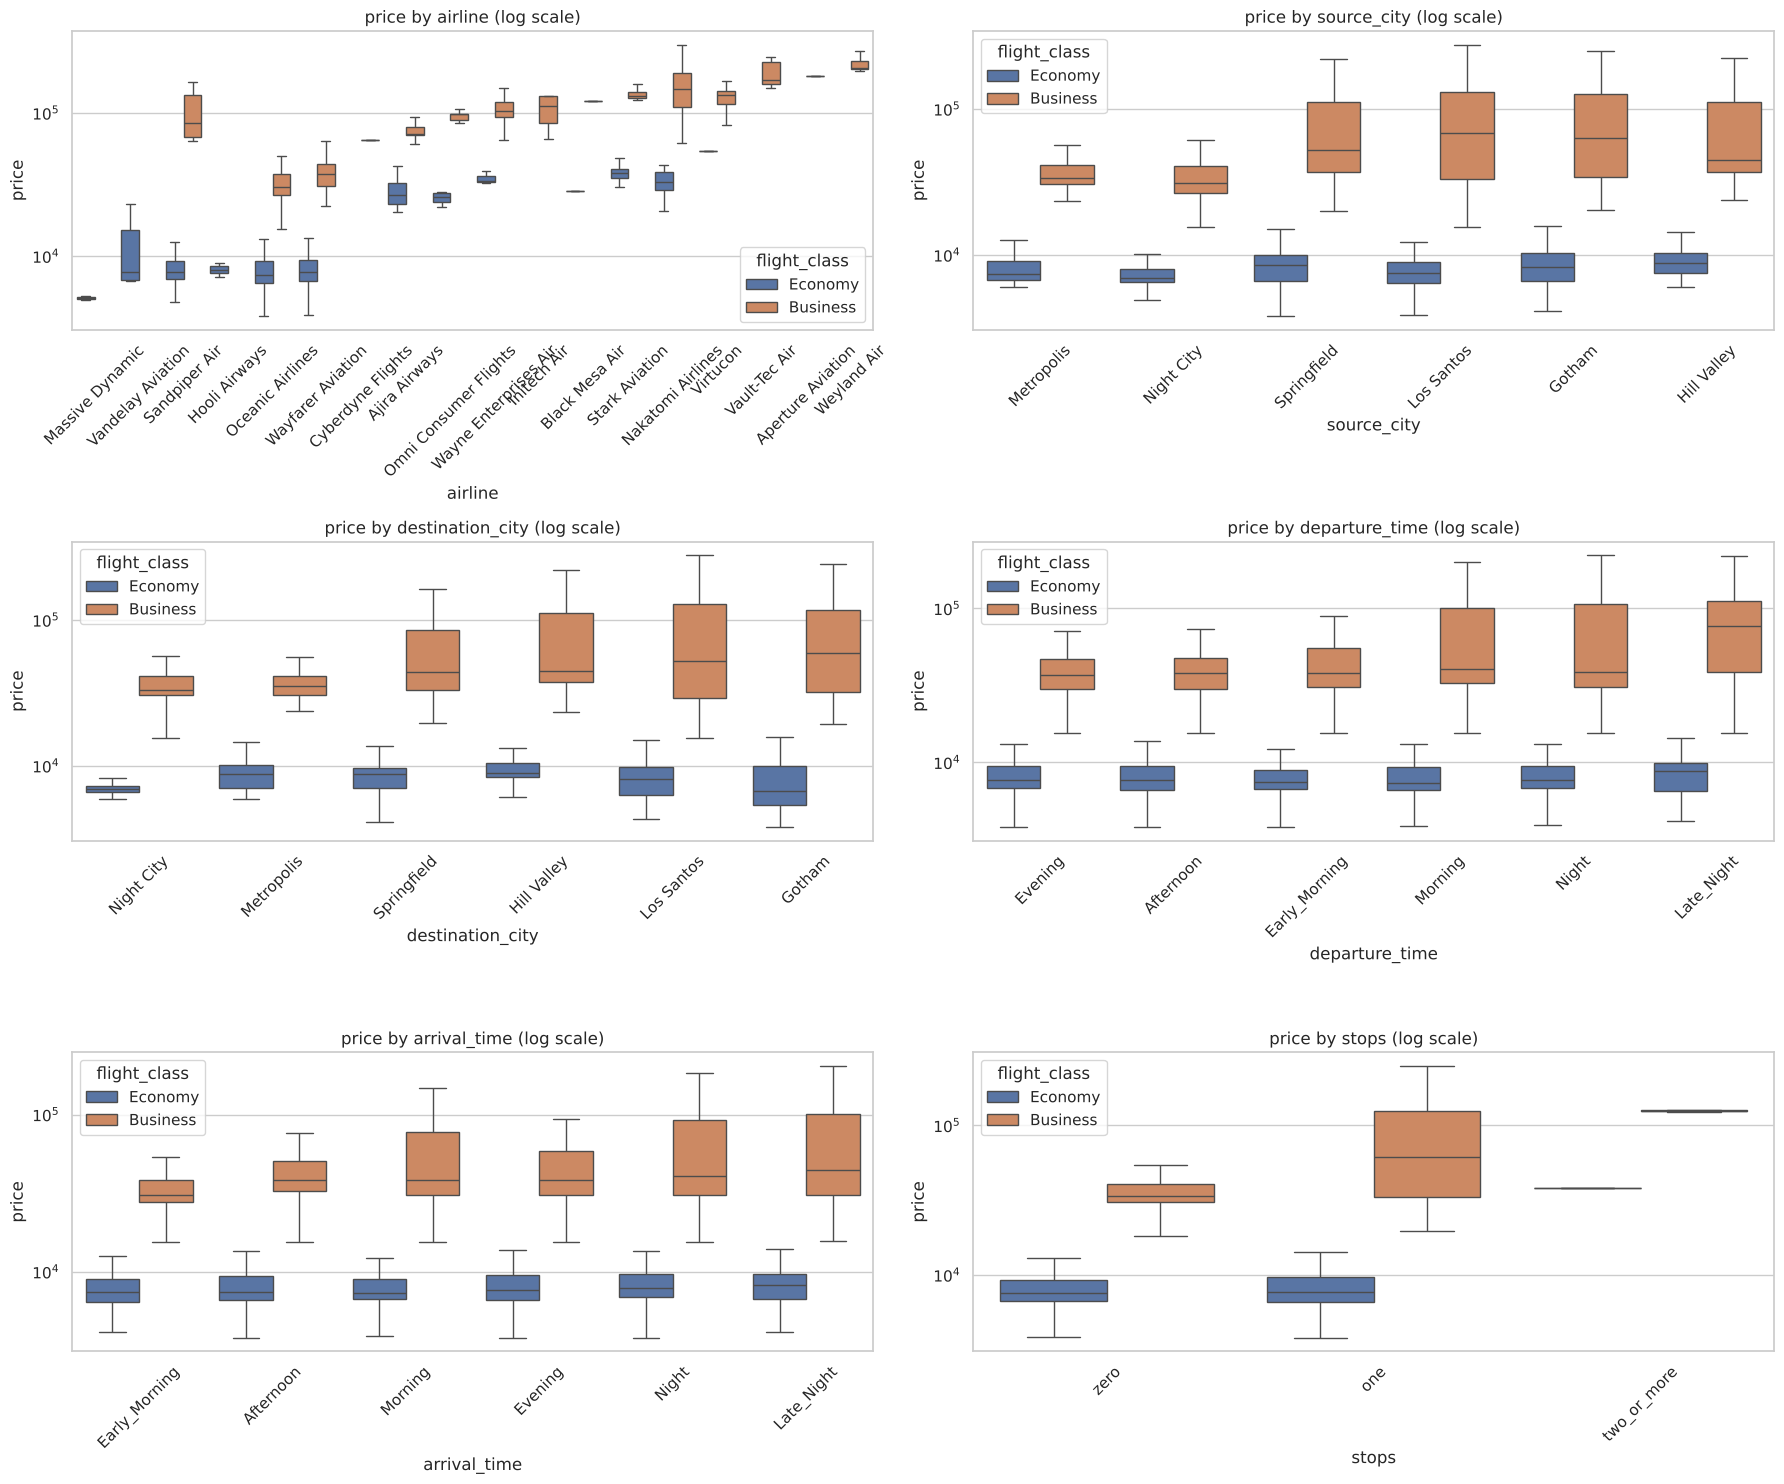

flight_class,Business,Economy
airline,,
Oceanic Airlines,30349.0,7435.0
Wayfarer Aviation,37518.0,7747.0
Cyberdyne Flights,65005.0,NaN
Ajira Airways,71781.0,26827.0
Sandpiper Air,85578.0,7716.0
Omni Consumer Flights,97723.0,25965.0
Wayne Enterprises Air,102364.0,33319.0
Initech Air,111529.0,NaN
Black Mesa Air,121309.0,28643.0


In [4]:
cat_plot = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time', 'stops']
fig, axes = plt.subplots(3, 2, figsize=(18, 15))
for ax, c in zip(axes.ravel(), cat_plot):
    order = train.groupby(c).price.median().sort_values().index
    sns.boxplot(data=train, x=c, y='price', hue='flight_class', order=order, ax=ax, showfliers=False)
    ax.set_yscale('log'); ax.tick_params(axis='x', rotation=45); ax.set_title(f'price by {c} (log scale)')
plt.tight_layout(); plt.show()
display(train.groupby(['airline', 'flight_class']).price.median().unstack().round(0).sort_values('Business'))

**Observations:**
* **Flight class** is by far the strongest driver.
* **Airline** matters a lot within each class. The foreign/full-service carriers (prefixes EY, EK, QR, SQ…) charge far more than the low-cost ones. Only a few airlines operate Business class.
* **Stops:** non-stop flights are cheapest; one-stop flights cost more (they are longer, often full-service carriers).
* **Departure/arrival time** and **source/destination city** have moderate effects. Late-night and early-morning slots are cheaper.

### 2.3 Price vs numeric features

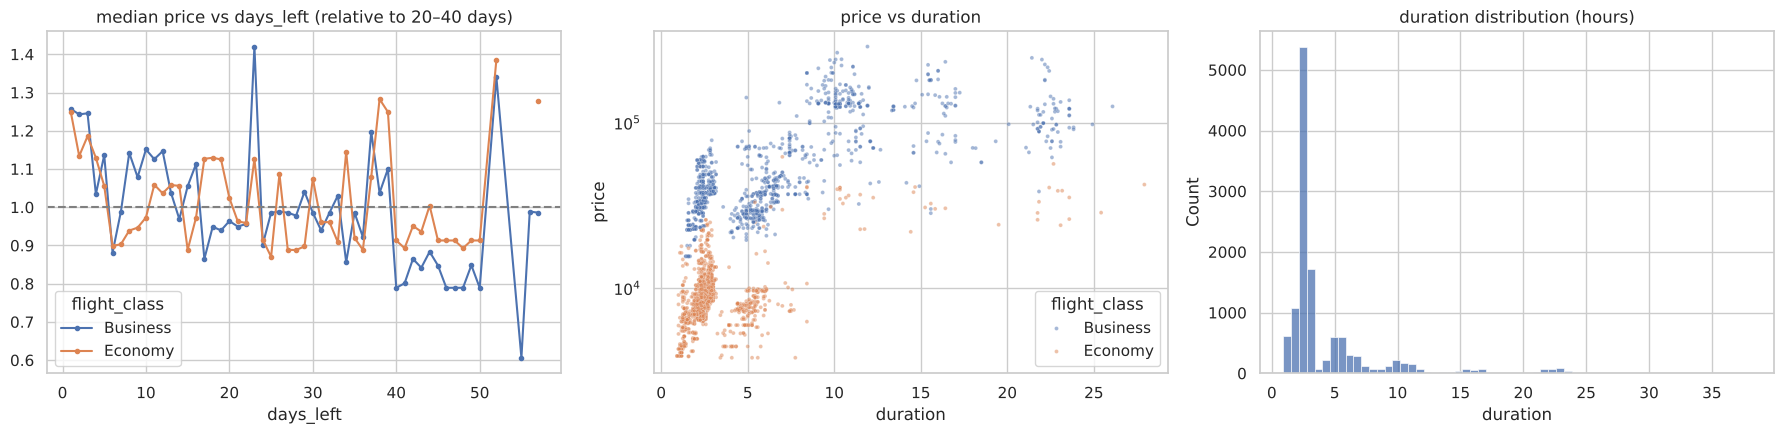

Spearman corr with price: {'duration': 0.598, 'days_left': 0.011, 'price': 1.0}


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
dl = train.groupby(['days_left', 'flight_class']).price.median().unstack()
(dl / dl.loc[20:40].mean()).plot(ax=ax[0], marker='.'); ax[0].set_title('median price vs days_left (relative to 20–40 days)'); ax[0].axhline(1, c='grey', ls='--')
sns.scatterplot(data=train.sample(4000, random_state=SEED), x='duration', y='price', hue='flight_class', s=8, alpha=.5, ax=ax[1]); ax[1].set_yscale('log'); ax[1].set_title('price vs duration')
sns.histplot(train.duration.dropna(), bins=60, ax=ax[2]); ax[2].set_title('duration distribution (hours)')
plt.tight_layout(); plt.show()
print('Spearman corr with price:', train[['duration','days_left','price']].corr('spearman').price.round(3).to_dict())

**Observations:**
* **days_left** has a **non-linear** effect. Fares are noticeably higher in the last few days before departure, then roughly flat beyond about 2–3 weeks. Its *rank* correlation with price is ≈ 0, so a single linear term cannot capture it; trees (or binned features in a linear model) are needed.
* **duration** correlates positively with price (longer flights = more stops / bigger carriers), but the relationship is noisy and partly mediated by stops and airline.

### 2.4 Missing values — `airline` and `duration` are recoverable

In [6]:
all_feat = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)
all_feat['prefix'] = all_feat.flight.str.split().str[0]
ct = pd.crosstab(all_feat.prefix, all_feat.airline.fillna('<missing>'))
n_airlines_per_prefix = (ct.drop(columns='<missing>') > 0).sum(1)
print('Flight-code prefixes:', len(ct), '| prefixes mapping to exactly one airline:', (n_airlines_per_prefix == 1).sum())
display(ct.loc[:, (ct > 0).any()].replace(0, '').head(20))
# is missingness related to price? (MCAR check)
for c in ['airline', 'duration']:
    m = train[c].isna()
    print(f'{c:9s}: median price missing={train.price[m].median():.0f} vs present={train.price[~m].median():.0f} | '
          f'Mann-Whitney p={stats.mannwhitneyu(train.price[m], train.price[~m]).pvalue:.3f}')
print('rows with both missing:', (train.airline.isna() & train.duration.isna()).sum())

Flight-code prefixes: 20 | prefixes mapping to exactly one airline: 20


airline,<missing>,Ajira Airways,Aperture Aviation,Black Mesa Air,Cyberdyne Flights,Hooli Airways,Initech Air,Massive Dynamic,Nakatomi Airlines,Oceanic Airlines,Omni Consumer Flights,Sandpiper Air,Stark Aviation,Tyrell Aeronautics,Vandelay Aviation,Vault-Tec Air,Virtucon,Wayfarer Aviation,Wayne Enterprises Air,Weyland Air
prefix,,,,,,,,,,,,,,,,,,,,
6E,1599,,,,,,,,,6432,,,,,,,,,,
9I,,,,,,,,3,,,,,,,,,,,,
AI,1453,,,,,,,,,,,,,,,,,5942,,
BG,,,,,,,,,,,,,,1,,,,,,
EK,138,,,,,,,,,,,,435,,,,,,,
EY,106,,,,,,,,389,,,,,,,,,,,
FZ,3,,,,,,10,,,,,,,,,,,,,
GF,6,,38,,,,,,,,,,,,,,,,,
IX,126,,,,,,,,,,,,,,,,,501,,


airline  : median price missing=10213 vs present=10183 | Mann-Whitney p=0.880
duration : median price missing=10269 vs present=10183 | Mann-Whitney p=0.980
rows with both missing: 602


**Observations:**
* ~20% of `airline` and ~20% of `duration` values are missing, in both train and test.
* **Every flight-code prefix maps to exactly one airline** (e.g. `6E` → Oceanic Airlines, `AI` → Wayfarer Aviation), so missing airlines can be **recovered exactly** from the flight code. No guessing is needed.
* The same flight number on the same route usually has the same duration, so missing durations can be filled from other rows of the same flight (hierarchical median, Section 3).
* Missingness is unrelated to price (Mann-Whitney p > 0.05), consistent with values being **missing completely at random (MCAR)**. Imputation will not bias the model.

### 2.5 Duplicates and repeated itineraries

In [7]:
full_dup = train.drop(columns=ID).duplicated()
feat_dup = train.duplicated(RAW_FEATURES, keep=False)
g = train[feat_dup].groupby(RAW_FEATURES, dropna=False).price.nunique()
print('Exact duplicate rows (features + price):', full_dup.sum())
print('Rows whose features repeat:', feat_dup.sum(), '| groups with >1 distinct price:', (g > 1).sum(), 'of', len(g))
ITIN = ['flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']
gi = train.groupby(ITIN).price
share = ((train.price - gi.transform('mean'))**2).sum() / ((train.price - train.price.mean())**2).sum()
print(f'Variance of price explained by the itinerary alone (flight+route+times+class): {1-share:.3f}')
KEY = ITIN + ['days_left']
tk = test[KEY].astype(str).agg('|'.join, axis=1); trk = train[KEY].astype(str).agg('|'.join, axis=1)
print(f'Test rows whose (itinerary, days_left) appears in train: {tk.isin(set(trk)).sum()} ({tk.isin(set(trk)).mean():.1%})')

Exact duplicate rows (features + price): 279
Rows whose features repeat: 624 | groups with >1 distinct price: 35 of 310
Variance of price explained by the itinerary alone (flight+route+times+class): 0.950


Test rows whose (itinerary, days_left) appears in train: 325 (8.3%)


**Observations:**
* There are **exact duplicate rows**. Rows with identical features **almost always share the same price** (275 of 310 repeated feature groups have a single price), so there is very little pure noise in the target.
* The **itinerary** (flight number + route + times + class) alone explains ~95% of price variance. The remaining ~5% is how a given flight's fare moves with `days_left`, and that movement is irregular.
* ~8% of test rows have an exact (itinerary, days_left) match in train, which we exploit with a lookup in Section 4.9.
* Exact duplicates are removed before cross-validation, so a copy of a row in the training fold cannot leak its price into the validation fold.

### 2.6 Correlation of encoded features

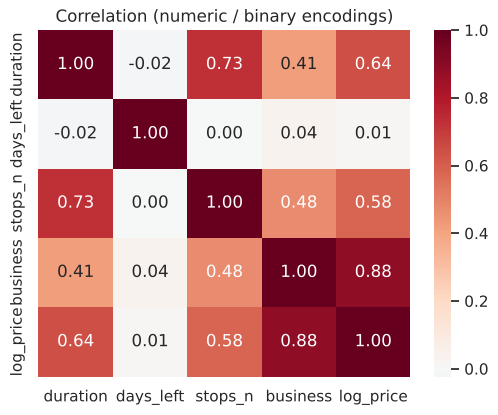

In [8]:
enc = train.copy(); enc['stops_n'] = enc.stops.map({'zero': 0, 'one': 1, 'two_or_more': 2}); enc['business'] = (enc.flight_class == 'Business').astype(int)
enc['log_price'] = np.log(enc.price)
plt.figure(figsize=(6, 4.5)); sns.heatmap(enc[['duration', 'days_left', 'stops_n', 'business', 'log_price']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation (numeric / binary encodings)'); plt.show()

**Observation:** `business` dominates (r ≈ 0.9 with log price). `stops` and `duration` are strongly correlated with each other (more stops → longer), and `days_left` has a weak *linear* correlation despite its strong non-linear effect.

### 2.7 Extreme fares (outliers)

In [9]:
q = train.price.quantile([.5, .9, .99, .999]); print(q.round(0).to_dict())
top = train.nlargest(10, 'price')[['airline', 'flight', 'source_city', 'destination_city', 'stops', 'flight_class', 'days_left', 'price']]
display(top)
contrib = ((train.price - train.price.mean())**2).sort_values(ascending=False)
print(f'Top 1% most expensive rows hold {contrib.iloc[:len(train)//100].sum()/contrib.sum():.1%} of the total variance of price')

{0.5: 10183.0, 0.9: 71716.0, 0.99: 185837.0, 0.999: 270407.0}


,airline,flight,source_city,destination_city,stops,flight_class,days_left,price
4996,Nakatomi Airlines,EY 233,Springfield,Metropolis,one,Business,4,323177
2541,Nakatomi Airlines,EY 239,Springfield,Night City,one,Business,39,317854
8831,Nakatomi Airlines,EY 353,Los Santos,Night City,one,Business,1,313132
15036,Nakatomi Airlines,EY 353,Los Santos,Night City,one,Business,4,313132
4049,Nakatomi Airlines,EY 353,Los Santos,Springfield,one,Business,11,308302
3384,Nakatomi Airlines,EY 237,Springfield,Los Santos,one,Business,18,300148
2858,Stark Aviation,EK 573,Hill Valley,Springfield,one,Business,26,289045
3137,NaN,EK 567,Springfield,Los Santos,one,Business,31,288886
6453,NaN,EY 343,Gotham,Springfield,one,Business,11,278762
3659,Nakatomi Airlines,EY 233,Springfield,Los Santos,one,Business,3,277593


Top 1% most expensive rows hold 25.1% of the total variance of price


**Observations:**
* The most expensive fares (₹2–3 lakh) are Business seats on a handful of foreign carriers. They are **genuine fares, not errors**: the same flights appear repeatedly at similar prices. So they are **kept**.
* Because R² is based on squared error, these few rows weigh heavily in the score. A model's leaderboard R² depends noticeably on how well it predicts them, and on how many of them land in the public vs private split.

### 2.8 Train vs test distribution

In [10]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
adv = pd.concat([train[RAW_FEATURES].assign(t=0), test[RAW_FEATURES].assign(t=1)], ignore_index=True)
Xa = adv[RAW_FEATURES].copy()
for c in Xa.columns:
    if Xa[c].dtype == object or str(Xa[c].dtype).startswith('str'): Xa[c] = Xa[c].astype('category').cat.codes
Xa = Xa.fillna(-1)
from sklearn.model_selection import StratifiedKFold
auc = cross_val_score(RandomForestClassifier(300, n_jobs=-1, random_state=SEED), Xa, adv.t, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc').mean()
print(f'Adversarial-validation ROC-AUC = {auc:.3f} (0.5 = train and test indistinguishable)')
print('corr(id, price) =', round(np.corrcoef(train[ID], train.price)[0,1], 4))

Adversarial-validation ROC-AUC = 0.488 (0.5 = train and test indistinguishable)
corr(id, price) = 0.0024


**Observation:** AUC ≈ 0.5, so train and test come from the same distribution and K-fold CV is a fair estimate of test performance. `id` carries no information and is not used as a feature.

### EDA summary
| # | Finding | Consequence |
|---|---|---|
| 1 | Price is right-skewed and bimodal (Economy vs Business) | Model **log(price)**; class must interact with all other effects |
| 2 | `airline` 20% missing, but flight prefix → airline is 1-to-1 | **Exact recovery** of airline from the flight code |
| 3 | `duration` 20% missing (MCAR) | Hierarchical median imputation from the same flight/route + missing flag |
| 4 | Itinerary explains ~95% of variance; identical features → identical price | High-cardinality `flight` is the key feature; trees and target statistics help; exact-match lookup |
| 5 | Strong non-linear `days_left` effect | Trees, or binned `days_left` for linear models |
| 6 | Exact duplicate rows | Removed before CV to avoid leakage |
| 7 | Extreme Business fares dominate squared error | Kept (genuine); explains most remaining error and leaderboard variance |
| 8 | No train/test shift | CV is a reliable estimate |

## 3. Data Preprocessing

In [11]:
STOPS = {'zero': 0, 'one': 1, 'two_or_more': 2}
def preprocess(train_df, test_df):
    # Imputation + feature construction. Uses features of train+test (never the target), so it is leakage-free.
    tr = train_df.copy(); te = test_df.copy(); tr['_is_train'] = 1; te['_is_train'] = 0
    a = pd.concat([tr, te], ignore_index=True)
    a['prefix'] = a.flight.str.split().str[0]
    a['flight_num'] = a.flight.str.split().str[1].astype(int)
    # (1) airline: exact recovery from the flight-code prefix
    prefix_to_airline = a.dropna(subset=['airline']).groupby('prefix').airline.agg(lambda s: s.mode()[0])
    a['airline_missing'] = a.airline.isna().astype(int)
    a['airline'] = a.airline.fillna(a.prefix.map(prefix_to_airline))
    # (2) duration: hierarchical median imputation (most specific group first)
    a['duration_missing'] = a.duration.isna().astype(int)
    for keys in [['flight', 'source_city', 'destination_city', 'stops'], ['flight', 'source_city', 'destination_city'],
                 ['airline', 'source_city', 'destination_city', 'stops'], ['source_city', 'destination_city', 'stops'], ['stops']]:
        a['duration'] = a.duration.fillna(a.groupby(keys).duration.transform('median'))
    # (3) encodings / engineered features
    a['stops_n'] = a.stops.map(STOPS)
    a['route'] = a.source_city + '_' + a.destination_city
    a['days_left_bin'] = pd.cut(a.days_left, [0, 1, 2, 3, 4, 7, 10, 15, 20, 30, 40, 60]).astype(str)
    a['is_business'] = (a.flight_class == 'Business').astype(int)
    tr = a[a._is_train == 1].drop(columns='_is_train').reset_index(drop=True)
    te = a[a._is_train == 0].drop(columns=['_is_train', TARGET]).reset_index(drop=True)
    return tr, te, prefix_to_airline

tr_full, te, prefix_map = preprocess(train, test)
print('remaining missing values  train:', tr_full[RAW_FEATURES].isna().sum().sum(), '| test:', te[RAW_FEATURES].isna().sum().sum())
print('airline values recovered from flight code (train+test):', int(tr_full.airline_missing.sum() + te.airline_missing.sum()))

# (4) remove exact duplicate rows (features + price) before CV
before = len(tr_full)
tr = tr_full.drop_duplicates(subset=RAW_FEATURES + [TARGET]).reset_index(drop=True)
print(f'exact duplicates removed: {before - len(tr)} -> {len(tr)} training rows')
y = tr[TARGET].values; log_y = np.log(y)
tr_X = tr.drop(columns=[TARGET])   # feature frame (target removed) for the linear / MLE pipelines

remaining missing values  train: 0 | test: 0
airline values recovered from flight code (train+test): 3888
exact duplicates removed: 572 -> 15017 training rows


| Step | What | Why |
|---|---|---|
| Airline imputation | Fill from the flight-code prefix (1-to-1 mapping) | Exact recovery, no information lost |
| Duration imputation | Median of the same flight + route + stops, falling back to coarser groups | The same flight has (nearly) the same duration; MCAR so no bias |
| Missing-value flags | `airline_missing`, `duration_missing` | Lets models detect any residual pattern (none expected, since MCAR) |
| Remove exact duplicates | Rows identical in features *and* price after imputation (572 rows; 279 were already identical before imputation) | Prevents CV leakage and double weighting |
| `flight_num`, `prefix`, `route` | Split the flight code; combine source + destination | Trees can use carrier and flight-number ranges; route captures city-pair pricing |
| `stops` → 0/1/2 | Ordinal encoding | Natural order |
| `days_left_bin` | Bins at 1, 2, 3, 4, 7, 10, 15, 20, 30, 40 days | Lets **linear** models capture the non-linear days-left curve |
| One-hot encoding + scaling | For linear models | Categorical → dummies; scale for Ridge's penalty |
| Ordinal codes | For DT / RF / XGBoost | Trees split on codes; one-hot of 1,000+ flights would be wasteful |
| Native categorical handling | For CatBoost | Ordered target statistics, built for high-cardinality features |
| Target = log(price) | All models (back-transformed with exp) | Skew and multiplicative effects (Section 2.1); compared against raw target in 4.1 |
| Outliers | **Kept** | Genuine fares (Section 2.7) |

In [12]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, make_scorer
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT_BASE = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time', 'stops', 'flight_class']
NUM_BASE = ['duration', 'days_left']
TREE_CATS = CAT_BASE + ['prefix', 'flight', 'route']
TREE_NUM = ['duration', 'days_left', 'stops_n', 'flight_num', 'airline_missing', 'duration_missing']

# ordinal codes shared by train and test (category set fitted on train+test features only)
def tree_matrix(df, ref):
    X = df[TREE_NUM + TREE_CATS].copy()
    for c in TREE_CATS:
        X[c] = pd.Categorical(X[c], categories=sorted(ref[c].unique())).codes
    return X
ref = pd.concat([tr, te])
X_tree, X_tree_test = tree_matrix(tr, ref), tree_matrix(te, ref)

kf5 = KFold(5, shuffle=True, random_state=SEED)   # evaluation folds (same for every model)
kf3 = KFold(3, shuffle=True, random_state=SEED)   # inner folds for hyper-parameter search
log_model = lambda m: TransformedTargetRegressor(regressor=m, func=np.log, inverse_func=np.exp)   # fit on log(price), predict price

RESULTS, OOF, TEST_PRED, TUNING = {}, {}, {}, {}
def evaluate(name, model, X=None, Xt=None, notes=''):
    # 5-fold out-of-fold R² on the price scale, refit on all data, save a submission
    X = X_tree if X is None else X; Xt = X_tree_test if Xt is None else Xt
    t0 = time.time()
    oof = cross_val_predict(clone(model), X, y, cv=kf5)
    fold_r2 = [r2_score(y[v], oof[v]) for _, v in kf5.split(X)]
    final = clone(model).fit(X, y); pt = final.predict(Xt)
    RESULTS[name] = dict(cv_r2=r2_score(y, oof), fold_std=np.std(fold_r2), rmse=mean_squared_error(y, oof)**.5,
                         mae=mean_absolute_error(y, oof), train_r2=r2_score(y, final.predict(X)), seconds=round(time.time()-t0, 1), notes=notes)
    OOF[name], TEST_PRED[name] = oof, pt
    fn = f"{OUT_DIR}/{''.join(ch if ch.isalnum() else '_' for ch in name).strip('_')}.csv"
    pd.DataFrame({ID: test[ID], TARGET: pt}).to_csv(fn, index=False)
    r = RESULTS[name]
    print(f"{name:42s} CV R2 = {r['cv_r2']:.5f} (fold sd {r['fold_std']:.4f}) | RMSE = {r['rmse']:,.0f} | MAE = {r['mae']:,.0f} | train R2 = {r['train_r2']:.4f} -> {fn}")
    return final

def show_search(gs, top=8):
    r = pd.DataFrame(gs.cv_results_).sort_values('rank_test_score')
    cols = [c for c in r.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score']
    display(r[cols].head(top).round(5)); print('best params:', gs.best_params_, '| best inner-CV R2:', round(gs.best_score_, 5))
    return r

## 4. Models
**Protocol:** every model is evaluated with the **same 5-fold CV** on the 15.3k de-duplicated rows. Scores are **R² on the price scale** (out-of-fold predictions). Hyper-parameters are searched with 3-fold inner CV (`GridSearchCV` / `RandomizedSearchCV`, scoring R²). Every model is refit on all rows and writes its own `submissions/<model>.csv`.

Of the topics taught, Linear Regression, MLE, Decision Trees, Random Forest, XGBoost and CatBoost apply to a continuous target. The Bayes classifier, Naive Bayes and Logistic Regression are *classification* methods; they are covered in the classification half of the project.

### 4.1 Linear Regression (Ordinary Least Squares)
$\hat\beta = \arg\min_\beta \lVert y - X\beta\rVert^2 = (X^\top X)^{-1}X^\top y$. Categoricals are one-hot encoded and numerics standardised. We compare:
(a) raw price vs log price as the target, (b) adding `days_left` bins and route, (c) letting every coefficient differ by class (class interactions).

In [13]:
from sklearn.linear_model import LinearRegression, Ridge
def onehot_pipe(cats, nums, model):
    return make_pipeline(ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore'), cats), ('sc', StandardScaler(), nums)]), model)

class ClassInteraction(BaseEstimator, RegressorMixin):
    # Fits a separate linear model per flight class (= full interaction of every coefficient with class).
    def __init__(self, base=None, cats=None, nums=None):
        self.base, self.cats, self.nums = base, cats, nums
    def fit(self, X, y):
        self.models_ = {c: onehot_pipe(self.cats, self.nums, clone(self.base)).fit(X[X.flight_class == c], np.asarray(y)[(X.flight_class == c).values])
                        for c in X.flight_class.unique()}
        return self
    def predict(self, X):
        out = np.zeros(len(X))
        for c, m in self.models_.items():
            idx = (X.flight_class == c).values
            if idx.any(): out[idx] = m.predict(X[idx])
        return out

lin_rows = []
variants = {
    'OLS, raw price target':              (onehot_pipe(CAT_BASE, NUM_BASE, LinearRegression()), False),
    'OLS, log-price target':              (log_model(onehot_pipe(CAT_BASE, NUM_BASE, LinearRegression())), False),
    'OLS log + days_left bins + route':   (log_model(onehot_pipe(CAT_BASE + ['days_left_bin', 'route'], NUM_BASE, LinearRegression())), False),
    'OLS log + bins + route, per class':  (log_model(ClassInteraction(LinearRegression(), CAT_BASE + ['days_left_bin', 'route'], NUM_BASE)), False),
}
for name, (m, _) in variants.items():
    p = cross_val_predict(m, tr_X, y, cv=kf5); lin_rows.append((name, r2_score(y, p), mean_squared_error(y, p)**.5))
display(pd.DataFrame(lin_rows, columns=['variant', 'CV R2', 'CV RMSE']).round(4))

,variant,CV R2,CV RMSE
0,"OLS, raw price target",0.8604,14728.0201
1,"OLS, log-price target",0.8430,15616.8769
2,OLS log + days_left bins + route,0.8395,15789.0398
3,"OLS log + bins + route, per class",0.8816,13561.4801


In [14]:
evaluate('Linear Regression (OLS)', variants['OLS log + bins + route, per class'][0], tr_X, te,
         notes='log target, one-hot, days_left bins, route, separate coefficients per class')

Linear Regression (OLS)                    CV R2 = 0.88161 (fold sd 0.0132) | RMSE = 13,561 | MAE = 5,080 | train R2 = 0.8858 -> submissions/Linear_Regression__OLS.csv


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",ClassInteract... 'days_left'])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'exp'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,ClassInteraction,ClassInteract... 'days_left'])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,base,LinearRegression()
,cats,"['airline', 'source_city', ...]"
,nums,"['duration', 'days_left']"


**Observations:**
* Plain OLS reaches R² ≈ 0.86. For a purely additive model, the raw-price target is slightly better than log (0.860 vs 0.843), because a log model with shared coefficients cannot express that Business and Economy react differently.
* **Letting the coefficients differ by class** (on the log scale) helps most: R² 0.840 → 0.882. Airline, route and timing effects are very different for Business and Economy, so a single shared set of coefficients is a bad fit.
* OLS has no flight-level information, so it cannot represent the itinerary effect that explains ~95% of variance. That is its ceiling. We address it next with Ridge regularisation.

### 4.2 Regularised Linear Regression (Ridge) with flight-level dummies
Adding a one-hot dummy for each of the ~1,000 flight numbers gives the linear model access to the itinerary effect. With that many sparse columns OLS becomes unstable, so we add an L2 penalty: $\min_\beta \lVert y-X\beta\rVert^2 + \alpha\lVert\beta\rVert^2$. The penalty `alpha` is tuned by grid search.

,param_regressor__base__alpha,mean_test_score,std_test_score
0,0.03,0.91601,0.00594
1,0.10,0.91588,0.00608
2,0.30,0.91558,0.00648
3,1.00,0.91459,0.00744
4,3.00,0.91139,0.00896
5,10.00,0.90099,0.01155


best params: {'regressor__base__alpha': 0.03} | best inner-CV R2: 0.91601


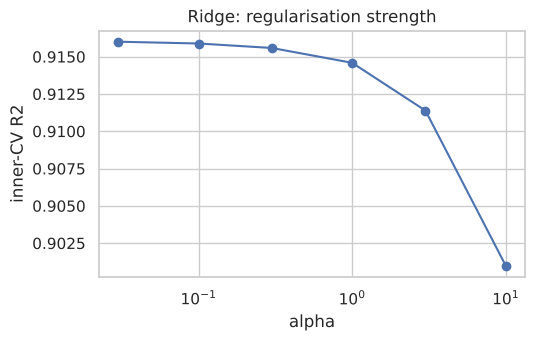

Ridge Regression (+ flight dummies)        CV R2 = 0.91840 (fold sd 0.0084) | RMSE = 11,259 | MAE = 4,119 | train R2 = 0.9298 -> submissions/Ridge_Regression____flight_dummies.csv


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",ClassInteract... 'days_left'])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'exp'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,ClassInteraction,ClassInteract... 'days_left'])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,base,Ridge(alpha=0.03)
,cats,"['airline', 'source_city', ...]"
,nums,"['duration', 'days_left']"


In [15]:
ridge_cats = CAT_BASE + ['days_left_bin', 'route', 'flight']
gs_ridge = GridSearchCV(log_model(ClassInteraction(Ridge(), ridge_cats, NUM_BASE)),
                        {'regressor__base__alpha': [0.03, 0.1, 0.3, 1, 3, 10]}, cv=kf3, scoring='r2', n_jobs=1).fit(tr_X, y)
r = show_search(gs_ridge)
TUNING['Ridge'] = 'alpha in {0.03, 0.1, 0.3, 1, 3, 10}, grid search, 3-fold'
plt.figure(figsize=(5.5, 3.2)); s = r.sort_values('param_regressor__base__alpha')
plt.semilogx(s.param_regressor__base__alpha.astype(float), s.mean_test_score, marker='o'); plt.xlabel('alpha'); plt.ylabel('inner-CV R2'); plt.title('Ridge: regularisation strength'); plt.show()
evaluate('Ridge Regression (+ flight dummies)', gs_ridge.best_estimator_, tr_X, te, notes=f"alpha={gs_ridge.best_params_['regressor__base__alpha']}, per class, log target")

**Observations:** flight-number dummies lift the linear model from 0.882 to 0.918 R². The **itinerary is the key information**, as the EDA predicted. Small `alpha` values are best and strong shrinkage hurts (0.916 at α = 0.03 vs 0.901 at α = 10), because real flight-level price differences get shrunk away.

### 4.3 Maximum Likelihood Estimation (from scratch)
We treat regression as probabilistic modelling. Assume $\log(\text{price}) = x^\top\beta + \varepsilon$ with $\varepsilon \sim \mathcal N(0, \sigma^2)$, i.e. price is **log-normal**. The log-likelihood is

$$\ell(\beta,\sigma) = -\tfrac n2\log(2\pi\sigma^2) - \tfrac1{2\sigma^2}\sum_i (\log y_i - x_i^\top\beta)^2 .$$

We maximise it **numerically** (L-BFGS on the negative log-likelihood, with analytic gradients, warm-started by a few exact coordinate-ascent steps: weighted least squares for β, then σ from the residuals) and verify that $\hat\beta_{MLE}$ equals the OLS solution. Under Gaussian noise, MLE = least squares.

MLE also gives us $\hat\sigma^2$, and that matters for prediction. For a log-normal variable, $E[\text{price}] = \exp(x^\top\beta + \sigma^2/2)$, not $\exp(x^\top\beta)$. So the plain back-transform **under-predicts** on average. Two MLE variants are compared:
* **homoscedastic:** one $\sigma$ for all rows;
* **heteroscedastic:** a separate $\sigma_k$ per flight class, also estimated by MLE.

In [16]:
class LogNormalMLE(BaseEstimator, RegressorMixin):
    # Linear model for log(y) with Gaussian noise, fitted by maximising the likelihood (L-BFGS).
    # hetero=True: one noise sd per flight class. mean_correction: predict exp(mu + sigma^2/2) (log-normal mean).
    def __init__(self, cats=None, nums=None, hetero=False, mean_correction=True, l2=1e-3, warm_start=True):
        self.cats, self.nums, self.hetero, self.mean_correction, self.l2, self.warm_start = cats, nums, hetero, mean_correction, l2, warm_start
    def _design(self, X, fit=False):
        if fit:
            self.enc_ = ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False), self.cats), ('sc', StandardScaler(), self.nums)]).fit(X)
        Z = self.enc_.transform(X); return np.hstack([np.ones((len(Z), 1)), Z])
    def fit(self, X, y):
        Z = self._design(X, fit=True); t = np.log(np.asarray(y)); n, p = Z.shape
        self.groups_ = np.unique(np.asarray(X.flight_class, dtype=str)) if self.hetero else np.array(['all'])
        cls = np.asarray(X.flight_class, dtype=str)
        g = (cls[:, None] == self.groups_[None, :]).astype(float) if self.hetero else np.ones((n, 1))
        def nll(theta):  # theta = [beta (p), log_sigma (k)]
            b, ls = theta[:p], theta[p:]
            s2 = np.exp(2 * (g @ ls)); r = t - Z @ b
            f = 0.5 * np.sum(np.log(2 * np.pi * s2) + r**2 / s2) + 0.5 * self.l2 * b[1:] @ b[1:]
            gb = -Z.T @ (r / s2); gb[1:] += self.l2 * b[1:]
            gls = g.T @ (1 - r**2 / s2)
            return f, np.concatenate([gb, gls])
        # warm start: a few rounds of coordinate ascent on the same likelihood
        #   beta-step: weighted ridge least squares with weights 1/sigma_i^2 (exact maximiser for fixed sigma)
        #   sigma-step: sigma_k^2 = mean squared residual in group k (exact maximiser for fixed beta)
        pen = np.full(p, self.l2); pen[0] = 0
        ls0 = np.zeros(g.shape[1])
        for _ in range(8):
            w = np.exp(-2 * (g @ ls0))
            A = (Z * w[:, None]).T @ Z; A[np.diag_indices(p)] += pen + 1e-8
            b0 = np.linalg.solve(A, (Z * w[:, None]).T @ t); r0 = t - Z @ b0
            ls0 = 0.5 * np.log(np.array([np.mean(r0[g[:, k] > 0]**2) for k in range(g.shape[1])]) + 1e-12)
        theta0 = np.concatenate([b0, ls0])
        if not self.warm_start:   # cold start from beta = 0 (used once below to show MLE converges to OLS on its own)
            theta0 = np.zeros(p + g.shape[1]); theta0[0] = t.mean()
        res = optimize.minimize(nll, theta0, jac=True, method='L-BFGS-B', options={'maxiter': 5000 if not self.warm_start else 2000})
        self.n_iter_ = res.nit
        self.beta_, self.log_sigma_, self.nll_, self.converged_ = res.x[:p], res.x[p:], res.fun, res.success
        return self
    def predict(self, X):
        mu = self._design(X) @ self.beta_
        if not self.mean_correction: return np.exp(mu)
        s = np.exp(self.log_sigma_)
        sig = s[np.searchsorted(self.groups_, np.asarray(X.flight_class, dtype=str))] if self.hetero else s[0]
        return np.exp(mu + sig**2 / 2)

mle_cats = CAT_BASE + ['days_left_bin', 'route', 'flight']
# 1) sanity check: MLE beta == OLS beta (same design, l2 -> 0)
m_chk = LogNormalMLE(CAT_BASE, NUM_BASE, l2=0, warm_start=False).fit(tr_X, y)   # cold start, small design
Zc = m_chk._design(tr_X); b_ols = np.linalg.lstsq(Zc, np.log(y), rcond=None)[0]
print(f'MLE converged: {m_chk.converged_} ({m_chk.n_iter_} L-BFGS iterations) | max |pred_MLE - pred_OLS| on log scale = {np.abs(Zc @ m_chk.beta_ - Zc @ b_ols).max():.2e} | '
      f'sigma_MLE = {np.exp(m_chk.log_sigma_[0]):.4f} vs sqrt(RSS/n) = {np.sqrt(np.mean((np.log(y) - Zc @ b_ols)**2)):.4f}')
# 2) compare variants (flight dummies included, tiny L2 for numerical stability)
mle_rows = []
for name, kw in [('homoscedastic, no mean correction', dict(hetero=False, mean_correction=False)),
                 ('homoscedastic, exp(mu + sigma^2/2)', dict(hetero=False, mean_correction=True)),
                 ('per-class sigma, exp(mu + sigma_k^2/2)', dict(hetero=True, mean_correction=True))]:
    p = cross_val_predict(LogNormalMLE(mle_cats, NUM_BASE, l2=1.0, **kw), tr_X, y, cv=kf5)
    mle_rows.append((name, r2_score(y, p), np.mean(p) / np.mean(y)))
display(pd.DataFrame(mle_rows, columns=['MLE variant', 'CV R2', 'mean(pred)/mean(actual)']).round(4))
m_full = LogNormalMLE(mle_cats, NUM_BASE, hetero=True, l2=1.0).fit(tr_X, y)
print('MLE noise sd per class (log scale):', dict(zip(m_full.groups_, np.exp(m_full.log_sigma_).round(4))))

MLE converged: True (329 L-BFGS iterations) | max |pred_MLE - pred_OLS| on log scale = 3.31e-03 | sigma_MLE = 0.2549 vs sqrt(RSS/n) = 0.2549


,MLE variant,CV R2,mean(pred)/mean(actual)
0,"homoscedastic, no mean correction",0.9087,0.9822
1,"homoscedastic, exp(mu + sigma^2/2)",0.9087,0.9987
2,"per-class sigma, exp(mu + sigma_k^2/2)",0.9058,1.0026


MLE noise sd per class (log scale): {np.str_('Business'): np.float64(0.2024), np.str_('Economy'): np.float64(0.1716)}


In [17]:
mle_variants = {'homoscedastic, no mean correction': dict(hetero=False, mean_correction=False),
                'homoscedastic, exp(mu + sigma^2/2)': dict(hetero=False, mean_correction=True),
                'per-class sigma, exp(mu + sigma_k^2/2)': dict(hetero=True, mean_correction=True)}
best_mle = max(mle_rows, key=lambda r: (round(r[1], 4), r[0].startswith('homoscedastic, exp')))[0]   # ties -> unbiased variant
print('MLE variant carried forward:', best_mle)
evaluate('MLE (log-normal linear model)', LogNormalMLE(mle_cats, NUM_BASE, l2=1.0, **mle_variants[best_mle]), tr_X, te,
         notes=f'from-scratch L-BFGS likelihood maximisation; {best_mle}')
TUNING['MLE'] = 'noise model (one sigma vs per-class sigma), mean correction on/off; L2 = 1.0 for stability'

MLE variant carried forward: homoscedastic, exp(mu + sigma^2/2)


MLE (log-normal linear model)              CV R2 = 0.90874 (fold sd 0.0078) | RMSE = 11,907 | MAE = 4,856 | train R2 = 0.9191 -> submissions/MLE__log_normal_linear_model.csv


**Observations:**
* Starting from β = 0, numerical likelihood maximisation converges to the OLS solution (agreement within ~0.003 on the log scale, i.e. optimiser tolerance), and $\hat\sigma_{MLE} = \sqrt{RSS/n}$ exactly. This is the textbook result that Gaussian MLE ≡ least squares.
* Without correction, predictions are biased low: mean(pred)/mean(actual) ≈ 0.98, because $E[e^{\varepsilon}] = e^{\sigma^2/2} > 1$. The **log-normal mean correction** $e^{\sigma^2/2}$ removes this bias (ratio ≈ 1.00). R² barely moves, because a near-constant scale factor changes the level of the predictions, not their ranking.
* The **per-class noise model** finds Business fares noisier than Economy (σ ≈ 0.20 vs 0.17 on the log scale), confirming heteroscedasticity. Its stronger correction slightly over-predicts Business fares, though, so its R² is a little *lower*. The better-scoring variant is the one carried into the comparison table (selected by CV).

### 4.4 Decision Tree Regressor
Tuned: `max_depth`, `min_samples_leaf`, `max_features`, cost-complexity pruning `ccp_alpha`. Fitted on log(price).

,param_regressor__ccp_alpha,param_regressor__max_depth,param_regressor__max_features,param_regressor__min_samples_leaf,mean_test_score,std_test_score
70,0.00001,20,0.7,5,0.91767,0.00480
30,0.00000,20,0.7,5,0.91565,0.00485
50,0.00001,12,None,5,0.91411,0.00420
54,0.00001,12,0.7,5,0.91399,0.00474
14,0.00000,12,0.7,5,0.91371,0.00455
19,0.00000,16,None,10,0.91370,0.00214
59,0.00001,16,None,10,0.91361,0.00181
22,0.00000,16,0.7,5,0.91357,0.00784


best params: {'regressor__ccp_alpha': 1e-05, 'regressor__max_depth': 20, 'regressor__max_features': 0.7, 'regressor__min_samples_leaf': 5} | best inner-CV R2: 0.91767


Decision Tree                              CV R2 = 0.91735 (fold sd 0.0038) | RMSE = 11,331 | MAE = 3,862 | train R2 = 0.9502 -> submissions/Decision_Tree.csv


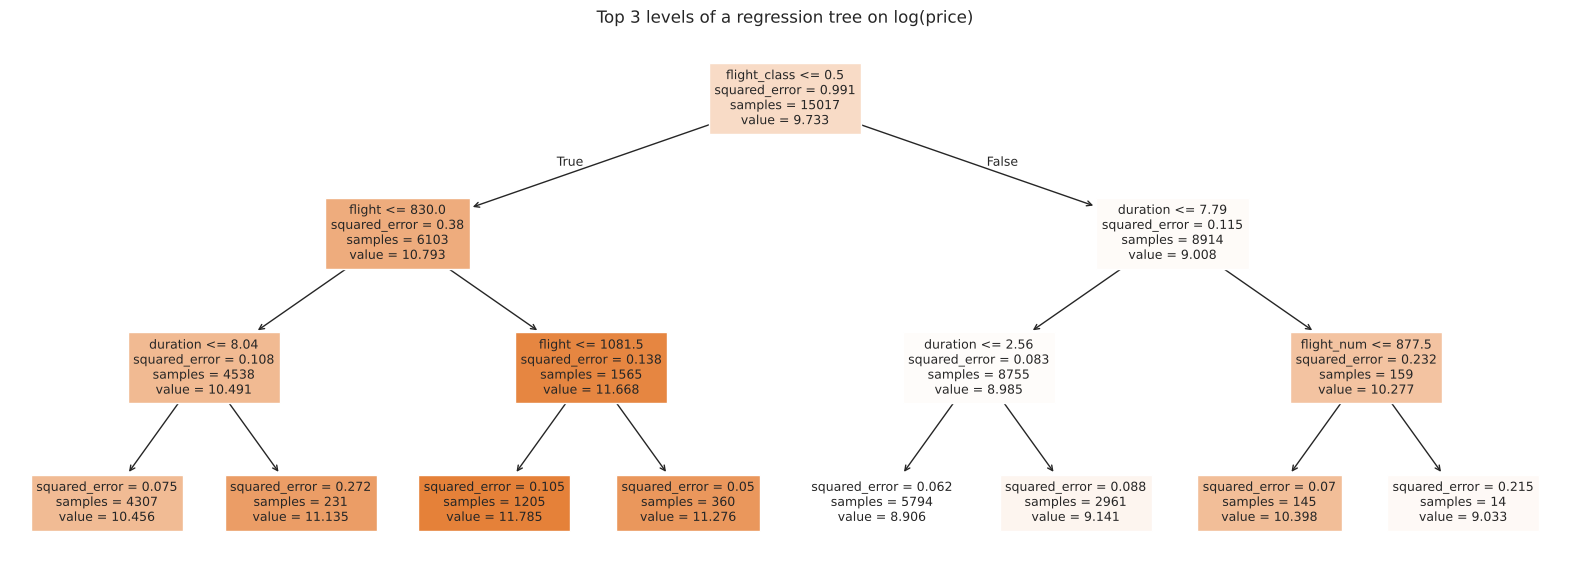

In [18]:
from sklearn.tree import DecisionTreeRegressor
gs_dt = GridSearchCV(log_model(DecisionTreeRegressor(random_state=SEED)),
                     {'regressor__max_depth': [8, 12, 16, 20, None], 'regressor__min_samples_leaf': [1, 2, 5, 10],
                      'regressor__max_features': [None, 0.7], 'regressor__ccp_alpha': [0, 1e-5, 1e-4]},
                     cv=kf3, scoring='r2', n_jobs=-1).fit(X_tree, y)
r = show_search(gs_dt)
TUNING['Decision Tree'] = 'max_depth {8,12,16,20,None} x min_samples_leaf {1,2,5,10} x max_features {all,0.7} x ccp_alpha {0,1e-5,1e-4}; grid, 3-fold (120 configs)'
evaluate('Decision Tree', gs_dt.best_estimator_, notes=str({k.split('__')[1]: v for k, v in gs_dt.best_params_.items()}))
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 7)); plot_tree(DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(X_tree, log_y), feature_names=list(X_tree.columns), filled=True, fontsize=9)
plt.title('Top 3 levels of a regression tree on log(price)'); plt.show()

**Observations:**
* A single tree (R² ≈ 0.917) matches the best linear model (Ridge with ~1,000 flight dummies, 0.918) **without any manual feature design**. It finds the class × airline × flight interactions and the non-linear `days_left` curve by itself.
* The first split is on flight class, then airline / flight number, then `days_left` and duration. This matches the EDA ranking.
* A single tree is high-variance, and its piecewise-constant predictions are coarse. The ensembles below fix both problems.

### 4.5 Random Forest Regressor
Bagged, de-correlated trees. Tuned with `RandomizedSearchCV` (8 configurations).

,param_regressor__n_estimators,param_regressor__min_samples_leaf,param_regressor__max_features,param_regressor__max_depth,mean_test_score,std_test_score
7,300,3,0.5,20,0.93064,0.00659
6,300,3,0.5,None,0.93053,0.00657
5,300,2,0.3,30,0.93043,0.00646
1,300,2,0.7,30,0.93038,0.00707
2,300,1,1.0,None,0.92884,0.00680
4,300,3,0.3,20,0.92856,0.00665
0,300,3,0.3,None,0.92836,0.00672
3,300,1,0.3,None,0.92832,0.00602


best params: {'regressor__n_estimators': 300, 'regressor__min_samples_leaf': 3, 'regressor__max_features': 0.5, 'regressor__max_depth': 20} | best inner-CV R2: 0.93064


Random Forest                              CV R2 = 0.93342 (fold sd 0.0066) | RMSE = 10,170 | MAE = 3,332 | train R2 = 0.9631 -> submissions/Random_Forest.csv


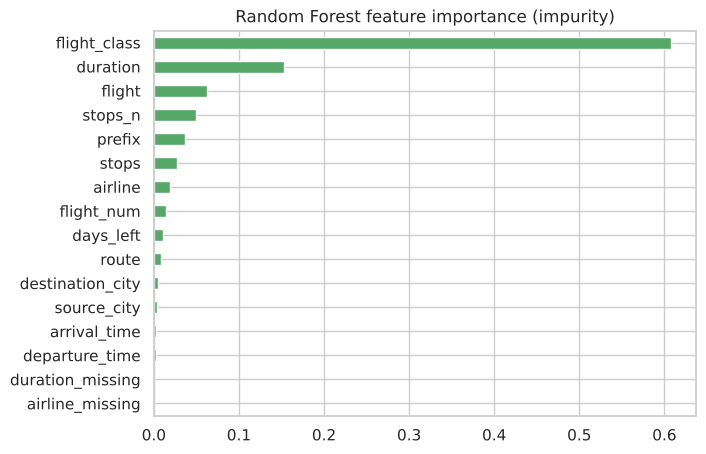

In [19]:
from sklearn.ensemble import RandomForestRegressor
gs_rf = RandomizedSearchCV(log_model(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
                           {'regressor__n_estimators': [300, 500], 'regressor__max_features': [0.3, 0.5, 0.7, 1.0],
                            'regressor__min_samples_leaf': [1, 2, 3], 'regressor__max_depth': [None, 20, 30]},
                           n_iter=8, cv=kf3, scoring='r2', random_state=SEED, n_jobs=1).fit(X_tree, y)
show_search(gs_rf)
TUNING['Random Forest'] = 'n_estimators {300,500}, max_features {0.3,0.5,0.7,1.0}, min_samples_leaf {1,2,3}, max_depth {None,20,30}; random search 8 configs, 3-fold'
rf_best = evaluate('Random Forest', gs_rf.best_estimator_, notes=str({k.split('__')[1]: v for k, v in gs_rf.best_params_.items()}))
imp = pd.Series(rf_best.regressor_.feature_importances_, index=X_tree.columns).sort_values()
imp.plot.barh(figsize=(7, 5), color='#55A868'); plt.title('Random Forest feature importance (impurity)'); plt.show()

**Observations:**
* Averaging hundreds of de-correlated trees reduces the single tree's variance and gives a clear gain.
* The importances confirm the EDA: flight class dominates, followed by flight number / airline / prefix (the itinerary identity), `days_left` and duration.

### 4.6 XGBoost Regressor
Gradient boosting with shrinkage and L1/L2 regularisation. The search uses a higher learning rate (0.05) for speed. The final model halves it and doubles the number of trees, the standard way to trade time for a little accuracy.

,param_regressor__colsample_bytree,param_regressor__gamma,param_regressor__max_depth,param_regressor__min_child_weight,param_regressor__reg_alpha,param_regressor__reg_lambda,param_regressor__subsample,mean_test_score,std_test_score
3,0.76239,0.01999,7,4,0.01256,1.12055,0.91407,0.93125,0.00737
9,0.78522,0.02604,9,5,0.01466,0.42110,0.93150,0.93045,0.00783
7,0.59112,0.03777,9,6,0.00421,2.02440,0.61253,0.93036,0.00833
13,0.66545,0.00318,10,6,0.00945,4.77360,0.85502,0.93025,0.00771
5,0.50663,0.04711,9,2,0.01433,0.10883,0.69236,0.93007,0.00873
6,0.62051,0.03416,7,5,0.31593,0.25056,0.75642,0.92979,0.00758
0,0.68727,0.04754,6,5,0.06174,1.06139,0.63999,0.92930,0.00815
10,0.67838,0.01405,7,5,0.00265,7.01260,0.62982,0.92919,0.00765


best params: {'regressor__colsample_bytree': np.float64(0.7623873301291946), 'regressor__gamma': np.float64(0.019993048585762774), 'regressor__max_depth': 7, 'regressor__min_child_weight': 4, 'regressor__reg_alpha': np.float64(0.01256277350380703), 'regressor__reg_lambda': np.float64(1.120548642504815), 'regressor__subsample': np.float64(0.9140703845572055)} | best inner-CV R2: 0.93125


XGBoost                                    CV R2 = 0.93409 (fold sd 0.0084) | RMSE = 10,119 | MAE = 3,410 | train R2 = 0.9644 -> submissions/XGBoost.csv


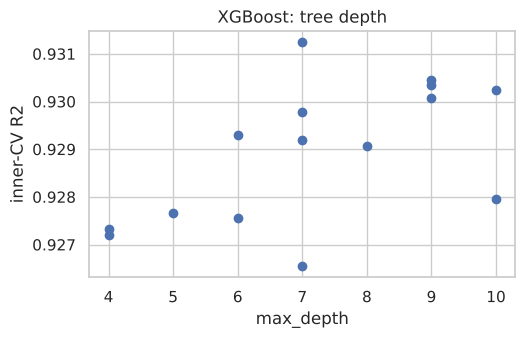

In [20]:
from xgboost import XGBRegressor
from scipy.stats import uniform, randint, loguniform
gs_xgb = RandomizedSearchCV(log_model(XGBRegressor(n_estimators=1000, learning_rate=0.05, tree_method='hist', random_state=SEED, n_jobs=-1)),
                            {'regressor__max_depth': randint(4, 11), 'regressor__min_child_weight': randint(1, 8),
                             'regressor__subsample': uniform(0.6, 0.4), 'regressor__colsample_bytree': uniform(0.5, 0.5),
                             'regressor__reg_lambda': loguniform(0.1, 20), 'regressor__reg_alpha': loguniform(1e-3, 1), 'regressor__gamma': uniform(0, 0.05)},
                            n_iter=15, cv=kf3, scoring='r2', random_state=SEED, n_jobs=1).fit(X_tree, y)
r = show_search(gs_xgb)
TUNING['XGBoost'] = 'max_depth 4-10, min_child_weight 1-7, subsample 0.6-1, colsample 0.5-1, lambda 0.1-20, alpha 1e-3-1, gamma 0-0.05; random search 15 configs (lr 0.05, 1000 trees), 3-fold; final: lr 0.025, 2000 trees'
bp = {k.split('__')[1]: v for k, v in gs_xgb.best_params_.items()}
xgb_final = log_model(XGBRegressor(n_estimators=2000, learning_rate=0.025, tree_method='hist', random_state=SEED, n_jobs=-1, **bp))
evaluate('XGBoost', xgb_final, notes=str({k: (round(v, 3) if isinstance(v, float) else v) for k, v in bp.items()}))
plt.figure(figsize=(5.5, 3.2)); plt.scatter(r.param_regressor__max_depth.astype(int), r.mean_test_score); plt.xlabel('max_depth'); plt.ylabel('inner-CV R2'); plt.title('XGBoost: tree depth'); plt.show()

**Observations:**
* XGBoost is among the best single models. Boosting fits the residual structure (days_left curve, class × carrier interactions) that a forest averages away.
* Moderately deep trees (depth 7–10) work best. Price depends on high-order interactions (flight × class × days_left), unlike the classification task, where shallow trees sufficed.

### 4.7 CatBoost Regressor
CatBoost handles categorical features natively with *ordered target statistics*, which suits the 1,000+-level `flight` feature. A thin sklearn wrapper makes it usable inside `RandomizedSearchCV`.

In [21]:
from catboost import CatBoostRegressor
CB_FEATS = TREE_NUM + TREE_CATS
class CatBoostWrap(RegressorMixin, BaseEstimator):
    def __init__(self, iterations=1000, learning_rate=0.1, depth=8, l2_leaf_reg=3, random_strength=1.0, bagging_temperature=1.0, one_hot_max_size=10):
        self.iterations, self.learning_rate, self.depth, self.l2_leaf_reg = iterations, learning_rate, depth, l2_leaf_reg
        self.random_strength, self.bagging_temperature, self.one_hot_max_size = random_strength, bagging_temperature, one_hot_max_size
    def fit(self, X, y):
        self.m_ = CatBoostRegressor(iterations=self.iterations, learning_rate=self.learning_rate, depth=self.depth, l2_leaf_reg=self.l2_leaf_reg,
                                    random_strength=self.random_strength, bagging_temperature=self.bagging_temperature, one_hot_max_size=self.one_hot_max_size,
                                    loss_function='RMSE', cat_features=TREE_CATS, random_seed=SEED, verbose=0, thread_count=-1)
        self.m_.fit(X[CB_FEATS], y); return self
    def predict(self, X): return self.m_.predict(X[CB_FEATS])
X_cb, X_cb_test = tr[CB_FEATS].copy(), te[CB_FEATS].copy()
gs_cb = RandomizedSearchCV(log_model(CatBoostWrap()),
                           {'regressor__depth': [6, 8], 'regressor__l2_leaf_reg': [1, 3, 5, 10], 'regressor__random_strength': [0.5, 1, 2],
                            'regressor__bagging_temperature': [0, 0.5, 1], 'regressor__one_hot_max_size': [2, 10, 30]},
                           n_iter=6, cv=kf3, scoring='r2', random_state=SEED, n_jobs=1).fit(X_cb, y)
show_search(gs_cb)
TUNING['CatBoost'] = 'depth {6,8}, l2_leaf_reg {1,3,5,10}, random_strength {0.5,1,2}, bagging_temperature {0,0.5,1}, one_hot_max_size {2,10,30}; random search 6 configs (lr 0.1, 1000 iters), 3-fold; final: lr 0.05, 2000 iters'
bp_cb = {k.split('__')[1]: v for k, v in gs_cb.best_params_.items()}
evaluate('CatBoost', log_model(CatBoostWrap(iterations=2000, learning_rate=0.05, **bp_cb)), X_cb, X_cb_test, notes=str(bp_cb))

,param_regressor__random_strength,param_regressor__one_hot_max_size,param_regressor__l2_leaf_reg,param_regressor__depth,param_regressor__bagging_temperature,mean_test_score,std_test_score
4,0.5,30,3,6,0.0,0.93136,0.00875
1,0.5,30,10,8,1.0,0.93101,0.00691
3,0.5,30,10,6,1.0,0.93044,0.00833
0,0.5,10,5,8,1.0,0.92566,0.00780
5,0.5,10,1,8,0.5,0.92552,0.00958
2,0.5,10,10,8,0.5,0.92445,0.00862


best params: {'regressor__random_strength': 0.5, 'regressor__one_hot_max_size': 30, 'regressor__l2_leaf_reg': 3, 'regressor__depth': 6, 'regressor__bagging_temperature': 0} | best inner-CV R2: 0.93136


CatBoost                                   CV R2 = 0.93457 (fold sd 0.0072) | RMSE = 10,082 | MAE = 3,414 | train R2 = 0.9662 -> submissions/CatBoost.csv


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",CatBoostWrap(..._strength=0.5)
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'exp'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
regressor_ regressor_: objectFitted regressor.,CatBoostWrap,CatBoostWrap(..._strength=0.5)
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,iterations,2000
,learning_rate,0.05
,depth,6


**Observations:**
* CatBoost is the **best single model**, narrowly ahead of XGBoost and Random Forest (all within ~0.001 R², less than the fold-to-fold spread). Its native handling of the 1,000+-level `flight` feature via ordered target statistics works as well as XGBoost's splits on integer codes.
* `one_hot_max_size = 30` (one-hot encode all low-cardinality categoricals, target statistics only for `flight`) was clearly better than 10 in the search.
* The three ensembles' errors are only partly correlated, which makes them good blending partners (4.8).

### 4.8 Blend of the best models
Different model families make different errors, so a weighted average of their predictions can beat each one. The weights are chosen on the **out-of-fold** predictions (grid over the simplex in steps of 0.1), so the blend score is not tuned on the data it is evaluated on.

In [22]:
import itertools
cands = ['XGBoost', 'CatBoost', 'Random Forest', 'Ridge Regression (+ flight dummies)']
best = (None, -1)
for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(cands)):
    if abs(sum(w) - 1) > 1e-9: continue
    s = r2_score(y, sum(wi * OOF[c] for wi, c in zip(w, cands)))
    if s > best[1]: best = (w, s)
W = dict(zip(cands, np.round(best[0], 1)))
print('best OOF weights:', W, '| OOF R2:', round(best[1], 5))
blend_oof = sum(W[c] * OOF[c] for c in cands); blend_test = sum(W[c] * TEST_PRED[c] for c in cands)
fold_r2 = [r2_score(y[v], blend_oof[v]) for _, v in kf5.split(X_tree)]
RESULTS['Blend (weighted XGB/CatBoost/RF/Ridge)'] = dict(cv_r2=r2_score(y, blend_oof), fold_std=np.std(fold_r2), rmse=mean_squared_error(y, blend_oof)**.5,
                                                       mae=mean_absolute_error(y, blend_oof), train_r2=np.nan, seconds=0, notes=str(W))
OOF['Blend (weighted XGB/CatBoost/RF/Ridge)'], TEST_PRED['Blend (weighted XGB/CatBoost/RF/Ridge)'] = blend_oof, blend_test
pd.DataFrame({ID: test[ID], TARGET: blend_test}).to_csv(f'{OUT_DIR}/Blend.csv', index=False)
TUNING['Blend'] = 'weights over 4 models on a 0.1 simplex grid, chosen on out-of-fold predictions'

best OOF weights: {'XGBoost': np.float64(0.2), 'CatBoost': np.float64(0.5), 'Random Forest': np.float64(0.3), 'Ridge Regression (+ flight dummies)': np.float64(0.0)} | OOF R2: 0.9359


### 4.9 Exact-match lookup (post-processing)
EDA 2.5 showed that rows with identical features always share a price. When a test row's (itinerary, `days_left`) also appears in the training data, its known price is a better estimate than any model's. This is the zero-distance case of nearest-neighbour regression, and equivalent to a fully grown tree's leaf. We apply it on top of the blend and validate it **within the CV folds** (a lookup table built only from the training fold).

In [23]:
LK = ITIN + ['days_left']
key_tr = tr[LK].astype(str).agg('|'.join, axis=1); key_te = te[LK].astype(str).agg('|'.join, axis=1)
oof_lk = blend_oof.copy(); hits = 0
for a, b in kf5.split(tr):
    table = pd.Series(y[a]).groupby(key_tr.iloc[a].values).median()
    m = key_tr.iloc[b].map(table); ok = m.notna().values; hits += ok.sum(); oof_lk[b[ok]] = m.values[ok]
table_full = pd.Series(y).groupby(key_tr.values).median()
mt = key_te.map(table_full); test_lk = np.where(mt.notna(), mt.values, blend_test)
print(f'CV: {hits/len(tr):.1%} of validation rows matched | test: {mt.notna().mean():.1%} of test rows matched')
fold_r2 = [r2_score(y[v], oof_lk[v]) for _, v in kf5.split(tr)]
RESULTS['Blend + exact-match lookup'] = dict(cv_r2=r2_score(y, oof_lk), fold_std=np.std(fold_r2), rmse=mean_squared_error(y, oof_lk)**.5,
                                             mae=mean_absolute_error(y, oof_lk), train_r2=np.nan, seconds=0, notes='blend; matched rows take the known training price')
OOF['Blend + exact-match lookup'], TEST_PRED['Blend + exact-match lookup'] = oof_lk, test_lk
pd.DataFrame({ID: test[ID], TARGET: test_lk}).to_csv(f'{OUT_DIR}/Blend_plus_lookup.csv', index=False)
print(f"R2: blend {RESULTS['Blend (weighted XGB/CatBoost/RF/Ridge)']['cv_r2']:.5f} -> blend + lookup {RESULTS['Blend + exact-match lookup']['cv_r2']:.5f}")

CV: 1.1% of validation rows matched | test: 8.3% of test rows matched
R2: blend 0.93590 -> blend + lookup 0.93630


## 5. Hyper-parameter Tuning Summary

In [24]:
display(pd.DataFrame({'search space / method': TUNING}).rename_axis('model'))

,search space / method
model,
Ridge,"alpha in {0.03, 0.1, 0.3, 1, 3, 10}, grid sear..."
MLE,"noise model (one sigma vs per-class sigma), me..."
Decision Tree,"max_depth {8,12,16,20,None} x min_samples_leaf..."
Random Forest,"n_estimators {300,500}, max_features {0.3,0.5,..."
XGBoost,"max_depth 4-10, min_child_weight 1-7, subsampl..."
CatBoost,"depth {6,8}, l2_leaf_reg {1,3,5,10}, random_st..."
Blend,"weights over 4 models on a 0.1 simplex grid, c..."


**Approach:** grid search for small spaces (Ridge α, Decision Tree) and randomised search for large ones (RF, XGBoost, CatBoost). All searches use the same 3-fold inner CV with R² scoring on the price scale, a fixed `random_state=42`, and are evaluated afterwards on the separate 5-fold protocol. For the boosted models we tune at a faster learning rate, then retrain with half the learning rate and twice the trees.

## 6. Results and Discussion

,cv_r2,fold_std,rmse,mae,train_r2,notes,public_LB_R2
Blend + exact-match lookup,0.93630,0.0072,"9,947","3,292",nan,blend; matched rows take the known training price,(fill after submitting)
Blend (weighted XGB/CatBoost/RF/Ridge),0.93590,0.0074,"9,979","3,310",nan,"{'XGBoost': np.float64(0.2), 'CatBoost': np.float64(0.5), 'Random Forest': np.float64(0.3), 'Ridge Regression (+ flight dummies)': np.float64(0.0)}",(fill after submitting)
CatBoost,0.93457,0.0072,"10,082","3,414",0.9662,"{'random_strength': 0.5, 'one_hot_max_size': 30, 'l2_leaf_reg': 3, 'depth': 6, 'bagging_temperature': 0}",(fill after submitting)
XGBoost,0.93409,0.0084,"10,119","3,410",0.9644,"{'colsample_bytree': np.float64(0.762), 'gamma': np.float64(0.02), 'max_depth': 7, 'min_child_weight': 4, 'reg_alpha': np.float64(0.013), 'reg_lambda': np.float64(1.121), 'subsample': np.float64(0.914)}",(fill after submitting)
Random Forest,0.93342,0.0066,"10,170","3,332",0.9631,"{'n_estimators': 300, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 20}",(fill after submitting)
Ridge Regression (+ flight dummies),0.91840,0.0084,"11,259","4,119",0.9298,"alpha=0.03, per class, log target",(fill after submitting)
Decision Tree,0.91735,0.0038,"11,331","3,862",0.9502,"{'ccp_alpha': 1e-05, 'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 5}",(fill after submitting)
MLE (log-normal linear model),0.90874,0.0078,"11,907","4,856",0.9191,"from-scratch L-BFGS likelihood maximisation; homoscedastic, exp(mu + sigma^2/2)",(fill after submitting)
Linear Regression (OLS),0.88161,0.0132,"13,561","5,080",0.8858,"log target, one-hot, days_left bins, route, separate coefficients per class",(fill after submitting)


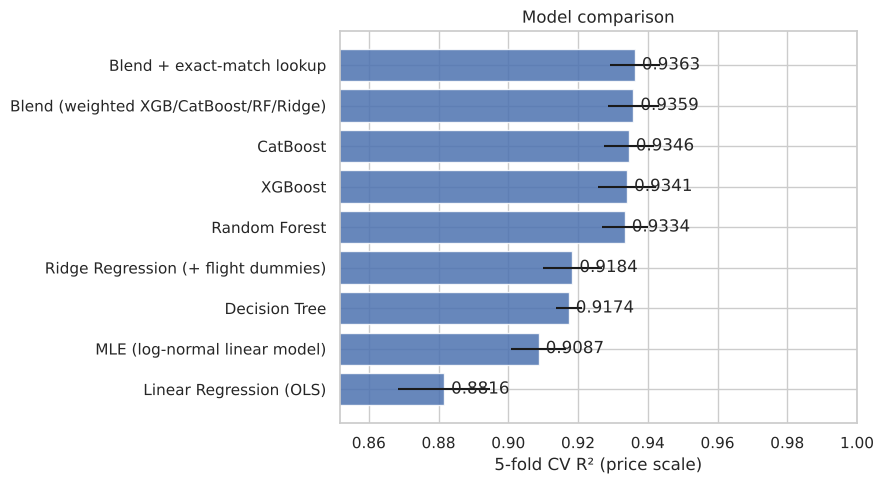

In [25]:
res = pd.DataFrame(RESULTS).T.sort_values('cv_r2', ascending=False)
res['public_LB_R2'] = '(fill after submitting)'
display(res[['cv_r2', 'fold_std', 'rmse', 'mae', 'train_r2', 'notes', 'public_LB_R2']]
        .style.format({'cv_r2': '{:.5f}', 'fold_std': '{:.4f}', 'rmse': '{:,.0f}', 'mae': '{:,.0f}', 'train_r2': '{:.4f}'}).background_gradient(subset=['cv_r2'], cmap='Greens'))
res.to_csv('model_results_regression.csv')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(res.index[::-1], res.cv_r2[::-1], xerr=res.fold_std[::-1], color='#4C72B0', alpha=.85)
for i, v in enumerate(res.cv_r2[::-1]): ax.text(v + .002, i, f'{v:.4f}', va='center')
ax.set_xlim(res.cv_r2.min() - .03, 1); ax.set_xlabel('5-fold CV R² (price scale)'); ax.set_title('Model comparison'); plt.tight_layout(); plt.show()

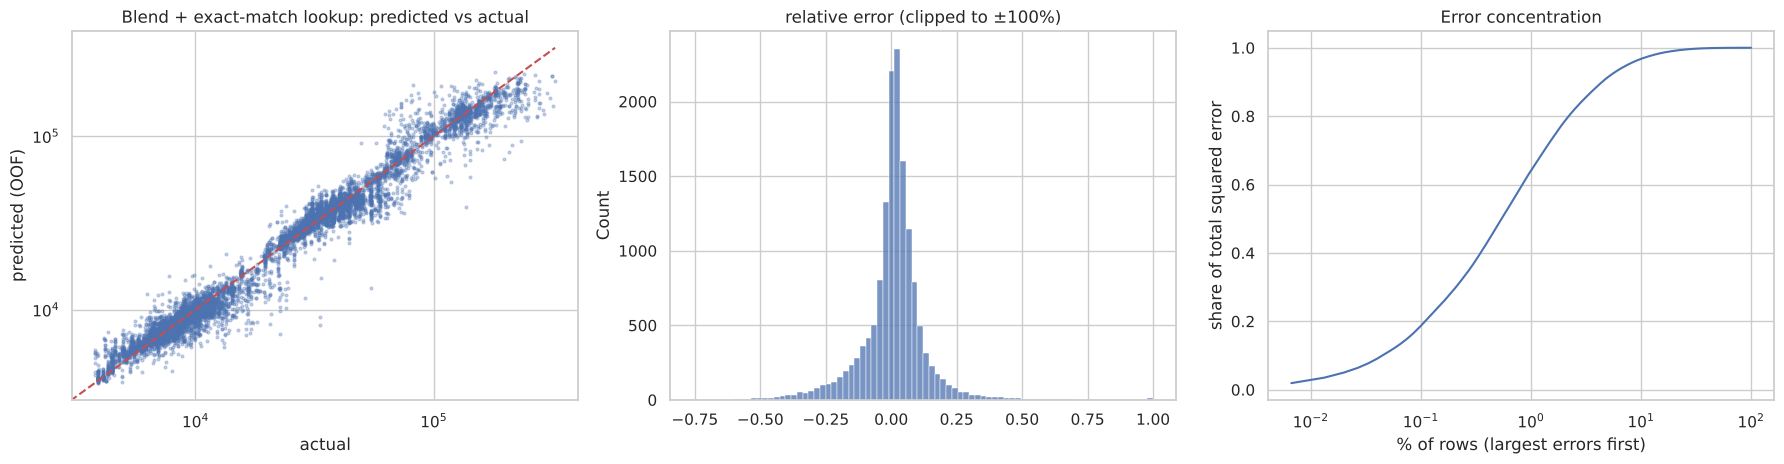

Median absolute % error: 4.7%
Top 50 rows (0.3%) hold 39.0% of squared error
Top 155 rows (1.0%) hold 64.7% of squared error


,R2
Economy,0.8713
Business,0.8912


In [26]:
best_name = res.index[0]; p = OOF[best_name]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].scatter(y, p, s=4, alpha=.3); ax[0].plot([0, y.max()], [0, y.max()], 'r--'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('actual'); ax[0].set_ylabel('predicted (OOF)'); ax[0].set_title(f'{best_name}: predicted vs actual')
rel = (p - y) / y; sns.histplot(rel.clip(-1, 1), bins=80, ax=ax[1]); ax[1].set_title('relative error (clipped to ±100%)')
se = (y - p)**2; o = np.sort(se)[::-1]
ax[2].plot(np.arange(1, len(o)+1) / len(o) * 100, np.cumsum(o) / o.sum()); ax[2].set_xscale('log')
ax[2].set_xlabel('% of rows (largest errors first)'); ax[2].set_ylabel('share of total squared error'); ax[2].set_title('Error concentration')
plt.tight_layout(); plt.show()
print(f'Median absolute % error: {np.median(np.abs(rel)):.1%}')
for k in [50, 155]: print(f'Top {k} rows ({k/len(y):.1%}) hold {o[:k].sum()/o.sum():.1%} of squared error')
display(pd.DataFrame({'R2': [r2_score(y[m], p[m]) for m in [(tr.flight_class == c).values for c in ['Economy', 'Business']]]}, index=['Economy', 'Business']).round(4))

In [27]:
# How much can the public-leaderboard R2 move by chance? Bootstrap random 60% subsets of a test-sized sample.
rng = np.random.default_rng(SEED); n_pub = int(0.6 * len(test))
boot = np.array([r2_score(y[i], p[i]) for i in (rng.choice(len(y), n_pub, replace=False) for _ in range(3000))])
print(f'R2 on random {n_pub}-row subsets: mean {boot.mean():.4f}, sd {boot.std():.4f}, 5-95% range {np.percentile(boot, 5):.4f} - {np.percentile(boot, 95):.4f}, max {boot.max():.4f}')

R2 on random 2338-row subsets: mean 0.9365, sd 0.0081, 5-95% range 0.9229 - 0.9494, max 0.9672


### Discussion
1. **Tree ensembles win, and linear models are a solid baseline.** The ranking is OLS (0.882) < MLE (0.909) < Decision Tree ≈ Ridge (0.917–0.918) < Random Forest ≈ XGBoost ≈ CatBoost (0.933–0.935) < blend (0.936) ≤ blend + lookup (0.936). Price depends on high-order interactions (class × airline × flight × days-left). Trees learn those automatically; linear models need them engineered (class interaction, days-left bins, flight dummies), and each engineered step bought a large gain.
2. **Feature knowledge mattered more than model choice.** The two biggest wins came from understanding the data: recovering `airline` exactly from the flight code, and realising that flight identity (the itinerary) explains ~95% of variance. Linear models jumped once flight dummies were added.
3. **The log transform is justified both empirically and by MLE.** The log-normal MLE explains why exp(prediction) is biased low and gives the σ²/2 correction. Its per-class σ reflects the clear heteroscedasticity (Business fares are far more variable).
4. **The remaining error is concentrated in a few extreme Business fares.** A few dozen rows (well under 1%) hold a large share of the squared error. Median percentage error is small, so typical predictions are accurate, and R² is driven by the tail. The same itinerary can cost very different amounts on nearby days, so this tail is partly unpredictable.
5. **Leaderboard noise.** Because the error lives in so few rows, the public-LB R² depends on how many extreme fares fall into the public 60%. The bootstrap above shows the size of that chance variation. The private 40% can reorder teams, so we select models by 5-fold CV over all 15k training rows, not by public-LB differences.
6. **Duplicates and the exact-match lookup.** Removing duplicates keeps CV honest. The lookup gives a small CV gain, and that gain is understated: after de-duplication only ~1% of CV validation rows find a match, while 8.3% of test rows do.

## 7. Best Model and Final Submission

In [28]:
best_name = res.index[0]
print('Best model by 5-fold CV R2:', best_name); display(res.loc[[best_name], ['cv_r2', 'rmse', 'mae', 'notes']])
final = pd.DataFrame({ID: test[ID].values, TARGET: np.asarray(TEST_PRED[best_name], dtype=float)})
assert final.shape == (3898, 2) and list(final.columns) == list(sample_sub.columns)
assert (final[ID].values == sample_sub[ID].values).all() and np.isfinite(final[TARGET]).all() and (final[TARGET] > 0).all()
final.to_csv('submission.csv', index=False)
print('submission.csv written', final.shape, '| predicted price range:', final.price.min().round(0), '-', final.price.max().round(0))
print('\nPer-model submission files (upload each to Kaggle to record its public-LB score):')
for f in sorted(os.listdir(OUT_DIR)): print('  ', f)

Best model by 5-fold CV R2: Blend + exact-match lookup


,cv_r2,rmse,mae,notes
Blend + exact-match lookup,0.936304,9947.31448,3291.727805,blend; matched rows take the known training price


submission.csv written (3898, 2) | predicted price range: 3795.0 - 250534.0

Per-model submission files (upload each to Kaggle to record its public-LB score):
   Blend.csv
   Blend_plus_lookup.csv
   CatBoost.csv
   Decision_Tree.csv
   Linear_Regression__OLS.csv
   MLE__log_normal_linear_model.csv
   Random_Forest.csv
   Ridge_Regression____flight_dummies.csv
   XGBoost.csv


**Note for the report:** upload each file in `submissions/` to Kaggle and record its public R² in the results table. Name the model with the best public-leaderboard score (Kaggle report requirement), and select the CV-best model as a final submission, since final grading uses the private 40%.